# Crop Yield Prediction - Multivariate Regression

**Mission:**
**Use Case:**
**Yield (tonnes per hetare)**
**Dataset:**
**Target:** `yield`

In [34]:
# 1. Imports

In [35]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.utils import shuffle

sns.set_style("whitegrid")

# 2. Loading the data  

In [36]:
DATA_PATH = "hvstat_africa_data_v1.0.csv"

df = pd.read_csv(DATA_PATH)

print("Raw shape:", df.shape)
df.head()

df.info()

Raw shape: (203125, 16)
<class 'pandas.DataFrame'>
RangeIndex: 203125 entries, 0 to 203124
Data columns (total 16 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   fnid                    203125 non-null  str    
 1   country                 203125 non-null  str    
 2   country_code            203125 non-null  str    
 3   admin_1                 203125 non-null  str    
 4   admin_2                 203125 non-null  str    
 5   product                 203125 non-null  str    
 6   season_name             203125 non-null  str    
 7   planting_year           203125 non-null  int64  
 8   planting_month          203125 non-null  int64  
 9   harvest_year            203125 non-null  int64  
 10  harvest_month           203125 non-null  int64  
 11  crop_production_system  203125 non-null  str    
 12  qc_flag                 203125 non-null  int64  
 13  area                    190428 non-null  float64
 14  product

# 3. Cleaning the data

In [37]:
print("Rows before cleaning:", len(df))

# 1. missing values
df = df.dropna(subset=["yield", "area"])
print("After dropping missing yield/area:", len(df))

# 2. zero or negative values
df = df[(df["yield"] > 0) & (df["area"] > 0)]
print("After dropping zero/negative:", len(df))

# 3. extreme yields
df = df[(df["yield"] <= 50)]
print("After removing yield > 50:", len(df))

# 4. old years
df = df[df["harvest_year"] >= 1995].copy()
print("After keeping 1995 onwards:", len(df))

Rows before cleaning: 203125
After dropping missing yield/area: 185430
After dropping zero/negative: 185430
After removing yield > 50: 184990
After keeping 1995 onwards: 160005


# Group rare categories

In [38]:
def keep_top(column, n):
    # keep the n most common values, replace everything with "Other"
    top_values = column.value_counts().nlargest(n).index
    return column.where(column.isin(top_values), "Other")

df["season_name"] = keep_top(df["season_name"], 9)
df["crop_production_system"] = keep_top(df["crop_production_system"], 5)

print(df["season_name"].value_counts())
print()
print(df["crop_production_system"].value_counts())

season_name
Main      68360
Annual    41588
Meher     13570
Other     13359
Wet        6932
Dry        6589
Summer     2644
Deyr       2501
Gu         2476
Long       1986
Name: count, dtype: int64

crop_production_system
All (PS)           69708
none               51461
Rainfed (PS)       20846
irrigated           8363
Other               7789
Commercial (PS)     1838
Name: count, dtype: int64


# Feature engineering: which columns we keep and drop

In [39]:
features = ["country", "product", "season_name", "crop_production_system",
            "planting_month", "harvest_month", "harvest_year", "area"]
target = "yield"

df = df[features + [target]].reset_index(drop=True)
print("Final shape:", df.shape)
print(df["country"].unique())
print("Rwanda rows:", (df["country"] == "Rwanda").sum())
df.head()

Final shape: (160005, 9)
<StringArray>
[                      'Angola',                 'Burkina Faso',
                      'Burundi',                        'Benin',
                          'DRC',     'Central African Republic',
                     'Cameroon',                     'Ethiopia',
                        'Ghana',                        'Kenya',
                      'Liberia',                      'Lesotho',
                   'Madagascar',                         'Mali',
                   'Mauritania',                       'Malawi',
                   'Mozambique',                        'Niger',
                      'Nigeria',                       'Rwanda',
                        'Sudan',                      'Senegal',
                      'Somalia',                  'South Sudan',
                         'Chad',                         'Togo',
 'Tanzania, United Republic of',                       'Uganda',
                 'South Africa',                   

,country,product,season_name,crop_production_system,planting_month,harvest_month,harvest_year,area,yield
0,Angola,Banana,Main,All (PS),10,4,2008,1364.0,14.360704
1,Angola,Banana,Main,All (PS),10,4,2009,1364.0,15.000733
2,Angola,Banana,Main,All (PS),10,4,2015,8706.0,25.504709
3,Angola,Banana,Main,All (PS),10,4,2016,8706.0,25.504709
4,Angola,Banana,Main,All (PS),10,4,2017,9549.7,24.499932


## 4. Visualizations 

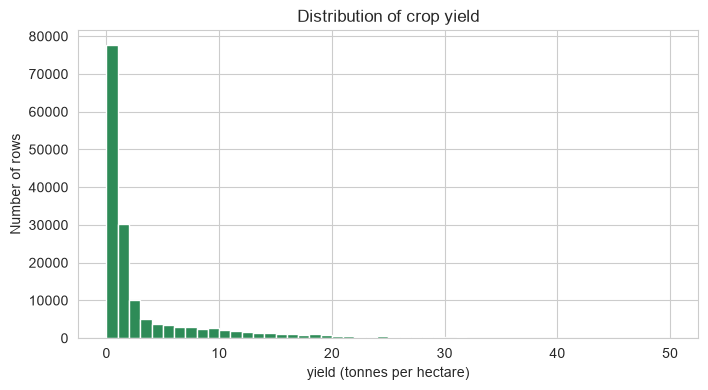

In [40]:
# Plot 1: Distribution of the target
plt.figure(figsize=(8,4))
plt.hist(df["yield"], bins=50, color="seagreen", edgecolor="white")
plt.xlabel("yield (tonnes per hectare)")
plt.ylabel("Number of rows")
plt.title("Distribution of crop yield")
plt.show()

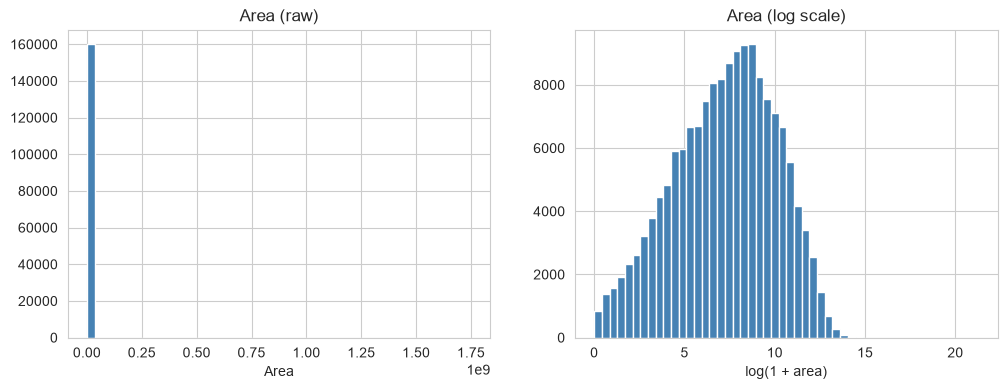

In [41]:
# Plot 2: area before and after a log transform
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["area"], bins=50, color="steelblue", edgecolor="white")
axes[0].set_title("Area (raw)")
axes[0].set_xlabel("Area")

axes[1].hist(np.log1p(df["area"]), bins=50, color="steelblue", edgecolor="white")
axes[1].set_title("Area (log scale)")
axes[1].set_xlabel("log(1 + area)")

plt.show()

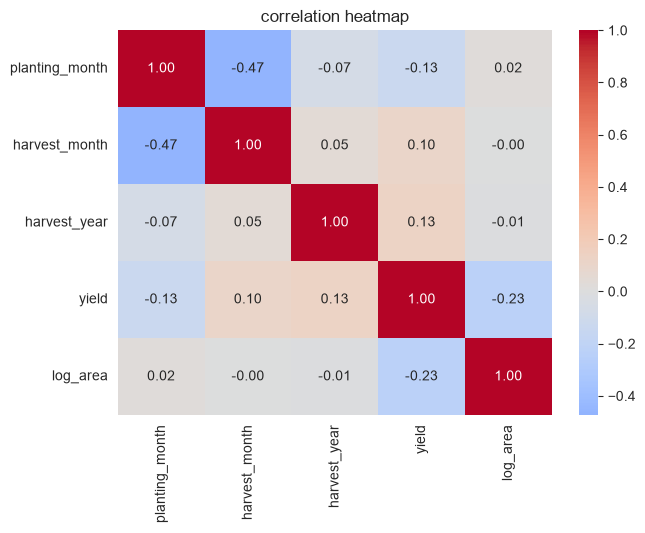

In [42]:
# Plot 3: correlation heatmap of the numeric columns
numeric_df = df[["planting_month", "harvest_month", "harvest_year", "area", "yield"]].copy()
numeric_df["log_area"] = np.log1p(numeric_df["area"])
numeric_df = numeric_df.drop(columns="area")

plt.figure(figsize=(7, 5))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("correlation heatmap")
plt.show()

## 5. Train / test split

In [43]:
train_df = df[df["harvest_year"] <= 2015]
test_df = df[df["harvest_year"] > 2015]

X_train = train_df[features]
y_train = train_df[target]
X_test = test_df[features]
y_test = test_df[target]

print("Train rows:", len(X_train))
print("Test rows:", len(X_test))
print("Test  share: {:.1%}".format(len(X_test) / len(df)))

Train rows: 124005
Test rows: 36000
Test  share: 22.5%


## 6. Convert categories to numbers and standardize

In [44]:
cat_cols = ["country", "product", "season_name", "crop_production_system"]
num_cols = ["planting_month", "harvest_month", "harvest_year"]

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ("num", StandardScaler(), num_cols),
    ("area", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), ["area"]),
])

# fit on train ONLY
X_train_s = preprocessor.fit_transform(X_train)
# the test set only gets transformed, never fitted
X_test_s = preprocessor.transform(X_test)

print("Train shape after preprocessor:", X_train_s.shape)
print("Test shape after preprocessing:", X_test_s.shape)

Train shape after preprocessor: (124005, 142)
Test shape after preprocessing: (36000, 142)


## 7. Model 1: SGDRegressor (Linear regression by gradient descent)

In [45]:
def train_sgd(eta0, alpha, epochs, loss="squared_error", epsilon=1.0):
    model = SGDRegressor(loss=loss, epsilon=epsilon, learning_rate="constant", eta0=eta0,
                         penalty="l2", alpha=alpha, random_state=42)
    train_losses = []
    test_losses = []

    for epoch in range(epochs):
        #shuffle the training data epoch
        X_shuf, y_shuf = shuffle(X_train_s, y_train, random_state=epoch)
        model.partial_fit(X_shuf, y_shuf)

        train_losses.append(mean_squared_error(y_train, model.predict(X_train_s)))
        test_losses.append(mean_squared_error(y_test, model.predict(X_test_s)))

    return model, train_losses, test_losses

In [46]:
learning_rates = [0.0001, 0.001, 0.01]
alphas = [0.0001, 0.01, 1.0]
EPOCHS = 30

results = []
for lr in learning_rates:
    for a in alphas:
        model, tr, te = train_sgd(lr, a, EPOCHS)
        results.append({
            "learning rate": lr,
            "alpha": a,
            "test MSE @ 5 epochs": te[4],
            "test MSE @ 15 epochs": te[14],
            "test MSE @ 30 epochs": te[29],
        })

tuning_table = pd.DataFrame(results)
tuning_table

,learning rate,alpha,test MSE @ 5 epochs,test MSE @ 15 epochs,test MSE @ 30 epochs
0,0.0001,0.0001,26.856473,23.426160,22.148027
1,0.0001,0.0100,28.722244,27.116696,26.940585
2,0.0001,1.0000,50.668782,50.333847,50.603190
3,0.0010,0.0001,21.506337,20.847040,21.027916
4,0.0010,0.0100,26.828738,26.825459,27.145720
5,0.0010,1.0000,51.170647,50.224551,50.860147
6,0.0100,0.0001,20.894962,20.932157,21.938990
7,0.0100,0.0100,27.222612,26.922010,28.657254
8,0.0100,1.0000,54.126457,49.201034,51.246647


In [47]:
best_row = tuning_table.loc[tuning_table["test MSE @ 30 epochs"].idxmin()]
best_lr = best_row["learning rate"]
best_alpha = best_row["alpha"]
print("Best learning rate:", best_lr, "Best alpha:", best_alpha)

# train again with the best settings and keep the loss history
sgd_model, sgd_train_losses, sgd_test_losses = train_sgd(best_lr, best_alpha, EPOCHS)

Best learning rate: 0.001 Best alpha: 0.0001


## Loss curve

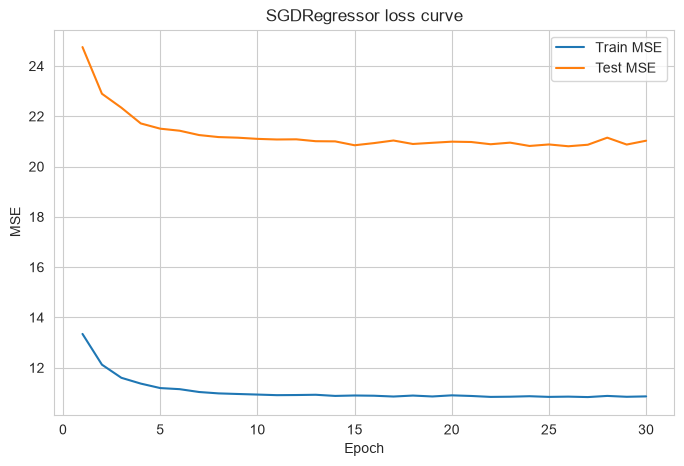

In [48]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), sgd_train_losses, label="Train MSE")
plt.plot(range(1, EPOCHS + 1), sgd_test_losses, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("SGDRegressor loss curve")
plt.legend()
plt.show()

## 8. Models 2,3 and 4

In [49]:
# Model 2: closed-form linear regression
lin_model = LinearRegression()
lin_model.fit(X_train_s, y_train)

# Model 3: decision tree
tree_model = DecisionTreeRegressor(max_depth=12, min_samples_leaf=5, random_state=42)
tree_model.fit(X_train_s, y_train)

#Model 4: random forest
# kept small (50 trees, limited depth) so the saved file is small enough to host
forest_model = RandomForestRegressor(n_estimators=50, max_depth=15, min_samples_leaf=5,
                                     n_jobs=-1, random_state=42)
forest_model.fit(X_train_s, y_train)

print("All models trained")

All models trained


## 9. Comparing the four models (same test set, MSE)

In [50]:
models = {
    "SGDRegressor": sgd_model,
    "LinearRegression": lin_model,
    "DecisionTree": tree_model,
    "RandomForest": forest_model,
}

rows = []
for name, model in models.items():
    train_mse = mean_squared_error(y_train, model.predict(X_train_s))
    test_mse = mean_squared_error(y_test, model.predict(X_test_s))
    rows.append({"Model": name, "Train MSE": train_mse, "Test MSE": test_mse})

comparison = pd.DataFrame(rows).sort_values("Test MSE").reset_index(drop=True)
comparison    

,Model,Train MSE,Test MSE
0,RandomForest,7.529289,18.198123
1,SGDRegressor,10.859337,21.027916
2,DecisionTree,9.915620,21.298062
3,LinearRegression,10.777801,22.783499


In [51]:
best_name = comparison.loc[0, "Model"]
print("Best model (lowest test MSE):", best_name)
print("Test MSE:", round(comparison.loc[0, "Test MSE"], 3))

Best model (lowest test MSE): RandomForest
Test MSE: 18.198


## 10. MSE vs Huber Loss

In [52]:
def huber_loss(y_true, y_pred, delta=1.0):
    error = np.array(y_true) - np.array(y_pred)
    abs_error = np.abs(error)

    small = 0.5 * error ** 2                     # used when error is small
    large = delta * (abs_error - 0.5 * delta)    # used when error is big/large

    return np.mean(np.where(abs_error <= delta, small, large))

#quick check: a small error and a big error
print("Huber for error of 0.5:", huber_loss([1.0], [1.5]))
print("Huber for error of 20:", huber_loss([1.0], [21.0]))
print("MSE for error of 20: ", mean_squared_error([1.0], [21.0]))

Huber for error of 0.5: 0.125
Huber for error of 20: 19.5
MSE for error of 20:  400.0


In [53]:
rows = []
for name, model in models.items():
    train_pred = model.predict(X_train_s)
    test_pred = model.predict(X_test_s)
    rows.append({
        "Model": name,
        "Train MSE": mean_squared_error(y_train,train_pred),
        "Test MSE": mean_squared_error(y_test, test_pred),
        "Train Huber": huber_loss(y_train, train_pred),
        "Test Huber": huber_loss(y_test, test_pred),
    })

loss_comparison = pd.DataFrame(rows).sort_values("Test MSE").reset_index(drop=True)
loss_comparison

,Model,Train MSE,Test MSE,Train Huber,Test Huber
0,RandomForest,7.529289,18.198123,0.978070,1.741614
1,SGDRegressor,10.859337,21.027916,1.269782,2.025759
2,DecisionTree,9.915620,21.298062,1.161536,1.932892
3,LinearRegression,10.777801,22.783499,1.264510,2.086635


## SGDRegressor trained with Huber loss

In [54]:
sgd_huber_model, huber_train_curve, huber_test_curve = train_sgd(
    best_lr, best_alpha, EPOCHS, loss="huber", epsilon=1.0)

for name, model in [("SGD trained with MSE", sgd_model), ("SGD trained with Huber", sgd_huber_model)]:
    test_pred = model.predict(X_test_s)
    print(name)
    print("  Test MSE:  ", round(mean_squared_error(y_test, test_pred), 3))
    print("  Test Huber:", round(huber_loss(y_test, test_pred), 3))

SGD trained with MSE
  Test MSE:   21.028
  Test Huber: 2.026
SGD trained with Huber
  Test MSE:   25.332
  Test Huber: 2.083


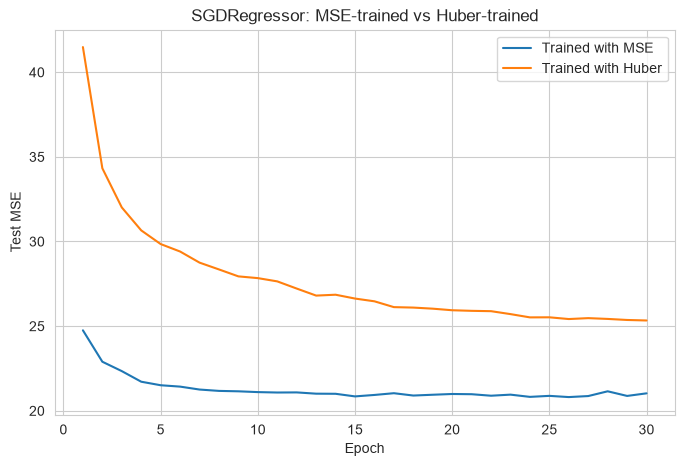

In [55]:
# the curves below record MSE per epoch for both versions
plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), sgd_test_losses, label="Trained with MSE")
plt.plot(range(1, EPOCHS + 1), huber_test_curve, label="Trained with Huber")
plt.xlabel("Epoch")
plt.ylabel("Test MSE")
plt.title("SGDRegressor: MSE-trained vs Huber-trained")
plt.legend()
plt.show()

## 11. Which features matter most?

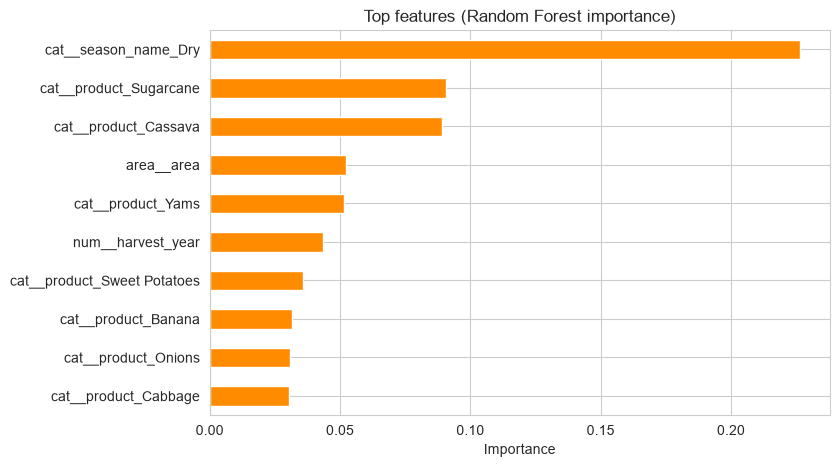

cat__season_name_Dry           0.226551
cat__product_Sugarcane         0.090657
cat__product_Cassava           0.089113
area__area                     0.052109
cat__product_Yams              0.051482
num__harvest_year              0.043309
cat__product_Sweet Potatoes    0.035637
cat__product_Banana            0.031729
cat__product_Onions            0.030688
cat__product_Cabbage           0.030249
dtype: float64

In [56]:
feature_names = preprocessor.get_feature_names_out()
importances = pd.Series(forest_model.feature_importances_, index=feature_names)
top10 = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
top10.sort_values().plot(kind="barh", color="darkorange")
plt.title("Top features (Random Forest importance)")
plt.xlabel("Importance")
plt.show()

top10

## 12. Scatter plots: Before and after the regression line

In [57]:
# find the numeric feature most correlated with yield (using log of area)
plot_df = train_df[["planting_month", "harvest_month", "harvest_year", "area", "yield"]].copy()
plot_df["log_area"] = np.log1p(plot_df["area"])
plot_df = plot_df.drop(columns="area")

correlations = plot_df.corr()["yield"].drop("yield")
top_feature = correlations.abs().idxmax()
print("Most correlated feature:", top_feature, "->", round(correlations[top_feature], 3))

# use a random sample of points so the plot is readable
sample = plot_df.sample(3000, random_state=42)

Most correlated feature: log_area -> -0.221


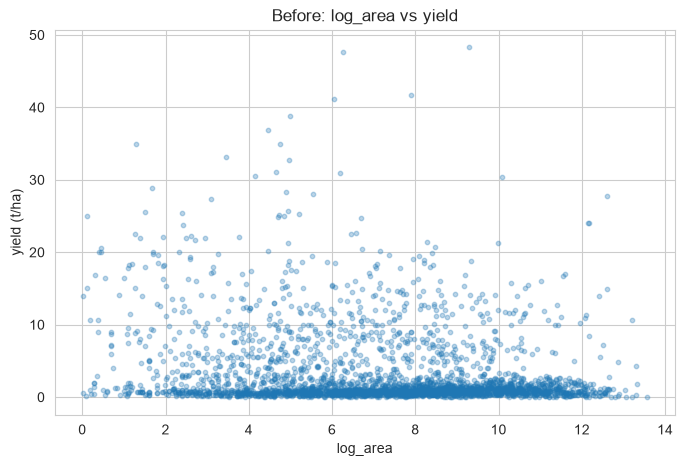

In [58]:
# Scatter Before
plt.figure(figsize=(8, 5))
plt.scatter(sample[top_feature], sample["yield"], alpha=0.3, s=10)
plt.xlabel(top_feature)
plt.ylabel("yield (t/ha)")
plt.title("Before: " + top_feature + " vs yield")
plt.show()

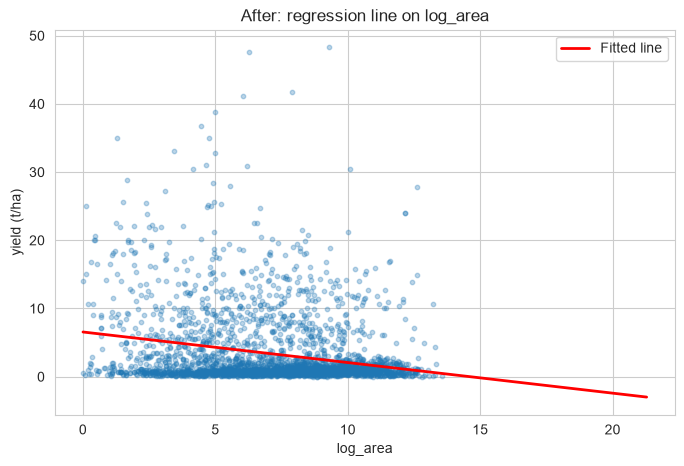

In [59]:
line_model = LinearRegression()
line_model.fit(plot_df[[top_feature]], plot_df["yield"])

x_line = np.linspace(plot_df[top_feature].min(), plot_df[top_feature].max(), 100)
y_line = line_model.predict(pd.DataFrame({top_feature: x_line}))

plt.figure(figsize=(8, 5))
plt.scatter(sample[top_feature], sample["yield"], alpha=0.3, s=10)
plt.plot(x_line, y_line, color="red", linewidth=2, label="Fitted line")
plt.xlabel(top_feature)
plt.ylabel("yield (t/ha)")
plt.title("After: regression line on " + top_feature)
plt.legend()
plt.show()

## 13. Saving the best model with its preprocessing

In [60]:
best_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", models[best_name]),
])

os.makedirs("../API", exist_ok=True)
joblib.dump(best_pipeline, "../API/best_model.pkl", compress=3)

size_mb = os.path.getsize("../API/best_model.pkl") / (1024 * 1024)
print("Saved best_model.pkl, size: {:.1f} MB".format(size_mb))

Saved best_model.pkl, size: 3.1 MB


## 14. Predict one row of the test set

In [61]:
def predict_one_row(row_number):
    # loading the saved pipeline
    loaded_model = joblib.load("../API/best_model.pkl")

    # take one row from the test set
    row = X_test.iloc[[row_number]]

    predicted = loaded_model.predict(row)[0]
    actual = y_test.iloc[row_number]

    print(row.to_string(index=False))
    print("Predicted yield: {:.2f} t/ha".format(predicted))
    print("Actual yield:    {:.2f} t/ha".format(actual))
    return predicted

predict_one_row(0)

country product season_name crop_production_system  planting_month  harvest_month  harvest_year   area
 Angola  Banana        Main               All (PS)              10              4          2016 8706.0
Predicted yield: 20.39 t/ha
Actual yield:    25.50 t/ha


np.float64(20.3912239139833)

## 15. Values the API will accept

In [62]:
for col in cat_cols:
    print(col, "->", sorted(df[col].unique()))
    print()

print(df[["planting_month", "harvest_month", "harvest_year", "area"]].describe().loc[["min", "max"]])

country -> ['Angola', 'Benin', 'Burkina Faso', 'Burundi', 'Cameroon', 'Central African Republic', 'Chad', 'DRC', 'Ethiopia', 'Ghana', 'Kenya', 'Lesotho', 'Liberia', 'Madagascar', 'Malawi', 'Mali', 'Mauritania', 'Mozambique', 'Niger', 'Nigeria', 'Rwanda', 'Senegal', 'Somalia', 'South Africa', 'South Sudan', 'Sudan', 'Tanzania, United Republic of', 'Togo', 'Uganda', 'Zambia', 'Zimbabwe']

product -> ['Avocado', 'Bambara groundnut', 'Banana', 'Barley', 'Bean (Hyacinth)', 'Beans (Rosecoco)', 'Beans (White)', 'Beans (mixed)', 'Beet', 'Bush Bean', 'Cabbage', 'Canola Seed', 'Capsicum Chinense', 'Carrots', 'Cashew (unshelled)', 'Cassava', 'Celery', 'Cereal Crops', 'Chick Peas', 'Chili Pepper', 'Coffee', 'Coriander', 'Cotton', 'Cotton (Acala)', 'Cotton (American)', 'Cottonseed', 'Cowpea', 'Cucumber', 'Eggplant', 'Ethiopian Cabbage', 'Fava Bean', 'Fenugreek', 'Field Peas', 'Fonio', 'Garlic', 'Geocarpa groundnut', 'Ginger', 'Goussi', 'Green Bean', 'Green Peppers', 'Groundnuts (In Shell)', 'Hops',